# 58장 · 필요한 Skill과 참고자료만 읽기

질문은 ‘대출 기간은 며칠인가요?’입니다. 전체 지침을 매번 넣는다면 보고서에만 쓰는 비교 자료까지 모델 입력에 들어갑니다. 여기서는 어떤 문서를 어느 시점에 읽었는지 추적합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 목록을 볼 때 공개할 정보

처음에는 작업의 이름과 설명만 보여 줍니다. 질문을 받은 뒤 필요한 Skill 본문을 읽고 그 안에서 지정한 참고자료를 엽니다. 전체 파일을 미리 넣는 방식과 같은 질문으로 비교하세요.

<!-- motion:foldout-reference -->
**참고자료는 언제 펼쳐 읽을까요?**

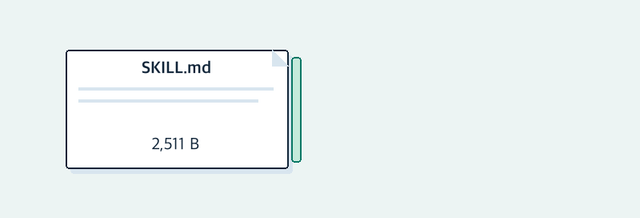

선택한 SKILL.md가 원문 대조를 요구할 때 references/source-check.md를 엽니다. 읽은 파일의 크기는 각각 2,511바이트와 1,049바이트입니다.
<!-- /motion -->


### 셀 01 · 선택한 지침만 읽기

파일 읽기를 작은 사전 조회로 표현했습니다. 선택한 이름이 어떤 본문으로 이어지나요?

In [1]:
files = {"evidence-answer/SKILL.md": "답변 전 references/source-check.md에서 원문 대조 기준을 읽는다.",
         "comparison-report/SKILL.md": "동일 조건의 두 실행 기록을 비교한다."}
chosen = "evidence-answer"
print(files[f"{chosen}/SKILL.md"])

답변 전 references/source-check.md에서 원문 대조 기준을 읽는다.


대출 질문을 처리할 때 읽은 본문에는 원문 대조 안내가 나옵니다. 비교 보고서의 본문은 이번 입력에 들어가지 않았습니다.

### 셀 02 · 실행 기록에서 읽은 양 구하기

앞선 실행에서 읽은 파일 두 개의 크기입니다. 바이트 단위로 합계를 구하세요.

In [2]:
reads = {"evidence-answer/SKILL.md": 2511,
         "evidence-answer/references/source-check.md": 1049}
print(sum(reads.values()))

3560


두 파일의 크기를 더한 3560바이트입니다. 이 값은 모델의 입력 토큰이나 청구 금액이 아닙니다. 실제 파일 읽기 기록은 loading-trace.json에 있습니다.

## 엉뚱한 비교 절차를 골랐을 때

‘비교’라는 단어 하나만 보고 Skill을 고르면 질문과 맞지 않을 수 있습니다. 선택한 이름, 읽은 참고자료, 인용한 원문 순서로 점검합니다. 선택과 읽기가 성공했어도 답의 의미는 따로 확인하세요.


### 과제 03 · 참고자료가 실제로 열렸나요?

필수 참고자료가 현재 읽기 기록에 들어 있는지 검사하세요. 본문을 열었다는 사실만으로는 충분하지 않습니다.

True는 제공된 읽기 기록에서 해당 경로를 찾았다는 뜻입니다. 지금 파일을 열어 확인한 결과와 구별하세요. 직접 읽기를 측정할 때에는 파일을 열어 본 뒤 그 시점의 경로를 실행 기록에 남깁니다.

In [3]:
reference = 'evidence-answer/references/source-check.md'
# reads에 reference가 있는지 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>reference = &#x27;evidence-answer/references/source-check.md&#x27;
print(reference in reads)</code></pre>
<p>실행 결과</p><pre><code>True</code></pre>
<p>True는 파일 읽기를 확인한 결과입니다. 14일이라고 답했는지는 답안 본문을 읽어야 알 수 있습니다.</p>
</details>

## 같은 질문으로 로더의 선택을 바꿔 보기

모든 본문을 전달하면 모델은 비교 작업용 절차까지 읽습니다. 아래에서는 작업 하나의 본문만 반환하는 함수를 만들고, 잘못 선택했을 때 무엇이 보이는지 확인합니다.


### 셀 04 · 비교 Skill을 잘못 선택한 경우

대출 기간 질문에 비교 보고서용 이름을 전달합니다.

In [4]:
def load_skill(name):
    return files[f"{name}/SKILL.md"]

print(load_skill("comparison-report"))

동일 조건의 두 실행 기록을 비교한다.


읽힌 지침에는 두 기록을 비교한다는 말만 있습니다. 파일 읽기는 성공했어도 대출 규정의 출처를 찾는 절차를 받을 수 없습니다.

### 셀 05 · 질문에 맞는 본문 길이와 전체 길이

같은 파일 모음에서 필요한 본문만 뽑았을 때 문자열 길이를 셉니다.

In [5]:
all_instructions = "\n".join(files.values())
selected = load_skill("evidence-answer")
print(len(selected), len(all_instructions))

48 70


첫 수는 대출 답변에 필요한 본문 길이, 둘째 수는 비교 지침까지 붙인 전체 길이입니다. Python의 문자 수이므로 모델의 실제 토큰 사용량은 따로 측정해야 합니다.

## 돌아보기

같은 자료로 비교 보고서를 요청한다면 필요한 입력이 두 실행 기록으로 바뀝니다. 목록에 남길 정보와 선택한 뒤 읽을 정보를 각각 한 가지씩 설명하세요.

### 이름·설명에서 근거까지

**이름·설명만 공개**　두 업무의 사용 상황과 현재 질문이 입력됩니다.

```
metadata + question
```

**선택한 Skill 전달**　load_skill의 ToolMessage가 추가됩니다.

```
evidence-answer/SKILL.md
```

**필수 참고자료 전달**　source-check를 읽고 선택 작성 노트는 읽지 않습니다.

```
references/source-check.md
```

**검색 결과와 초안**　R1 근거를 받은 뒤 초안을 반환하고 코드가 A1을 확인합니다.

```
library-1 → AnswerDraft → A1
```
